# Proyecto 2. Clasificación de señales ECG

## Punto 2. Base de datos

**Qué pide el enunciado:**
- Descargar `ECGData.zip` del mismo sitio del proyecto 1. A diferencia de `ECGDataDenoised`, estas señales están **sin filtrar**: el filtrado se programa en el punto 3.
- Seleccionar las mismas arritmias del proyecto 1.
- Trabajar con la **derivación II**.

**Qué se hace:**
1. Se cargan los mismos pacientes del subconjunto del proyecto 1 (`subconjunto_punto2.csv`): SB, SR, AFIB, ST y SVT, de 40 a 89 años. Usar los mismos pacientes permite, en el punto 3, comparar cada señal filtrada por nosotros con su versión de `ECGDataDenoised`.
2. Los cinco ritmos se agrupan en las **cuatro clases** que piden los puntos 5 y 7, siguiendo a Zheng *et al.* (2020).
3. Se revisa que la derivación II de cada archivo de `ECGData` sea válida: que exista, tenga 5.000 muestras y no esté vacía ni plana.
4. Se guarda la lista de pacientes válidos en `pacientes_proyecto2.csv`.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import time
from scipy import signal
FS = 500                                        # Hz
N_MUESTRAS = 5000                               # 10 s a 500 Hz
DERIVACION_II = 1                               # columnas: I, II, III, aVR, aVL, aVF, V1..V6
RUTA_ECGDATA = Path("ECGData")                  # carpeta descomprimida de ECGData.zip (señales sin filtrar)
RUTA_DENOISED = Path("ECGDataDenoised")         # carpeta del proyecto 1 (se usa en el punto 3)
RUTA_SUBCONJUNTO = Path("subconjunto_punto2.csv")
RITMOS = ["SB", "SR", "AFIB", "ST", "SVT"]

### 2.1 Pacientes y clases

El proyecto 1 usó cinco ritmos, pero los puntos 5 y 7 piden clasificar **cuatro patologías**. Zheng *et al.* (2020), el artículo de la base, agrupa los ritmos en cuatro clases:

| Clase | Ritmos que incluye en el artículo | Ritmos de este trabajo |
|---|---|---|
| SB | Bradicardia sinusal | SB |
| AFIB | Fibrilación y flutter auricular | AFIB |
| GSVT | Taquicardias supraventriculares (SVT, AT, AVNRT, AVRT, SAAWR, ST) | ST + SVT |
| SR | Ritmo sinusal e irregularidad sinusal | SR |

Por eso ST y SVT se unen en la clase **GSVT**. Así se conservan los mismos pacientes del proyecto 1 y se obtienen las cuatro clases.

In [24]:
subconjunto = pd.read_csv("subconjunto_punto2.csv")

clases = {"SB": "SB", "SR": "SR", "AFIB": "AFIB", "ST": "GSVT", "SVT": "GSVT"}
subconjunto["Clase"] = subconjunto["Rhythm"].map(clases)

print("Pacientes del subconjunto:", len(subconjunto))
print("\nPor ritmo:")
print(subconjunto["Rhythm"].value_counts())
print("\nPor clase:")
print(subconjunto["Clase"].value_counts())

Pacientes del subconjunto: 8288

Por ritmo:
Rhythm
SB      3493
AFIB    1700
SR      1467
ST      1174
SVT      454
Name: count, dtype: int64

Por clase:
Clase
SB      3493
AFIB    1700
GSVT    1628
SR      1467
Name: count, dtype: int64


### 2.2 Lectura de la derivación II de `ECGData`

`revisar_senal` intenta leer la derivación II de un paciente y, en vez de detener el proceso cuando algo falla, devuelve el motivo:
- **No existe:** el archivo no está en la carpeta.
- **Incompleta:** no tiene 5.000 muestras.
- **Vacía o plana:** tiene valores faltantes (NaN) o es una línea constante.
- **OK:** la señal se puede usar.

Los archivos pueden venir con o sin fila de encabezado (I, II, III…), así que la función contempla los dos casos.

In [25]:
def leer_derivacion_ii(nombre_o_ruta, carpeta=None):
    """Lee solo la derivación II.
    Acepta la ruta completa del archivo, o el nombre del paciente y la carpeta."""
    if carpeta is None:
        ruta = Path(nombre_o_ruta)                       # se pasó la ruta completa
    else:
        ruta = Path(carpeta) / f"{nombre_o_ruta}.csv"     # se pasó el nombre y la carpeta
    with open(ruta) as archivo:                            # se mira solo la primera línea
        primera = archivo.readline().split(",")
    try:
        float(primera[DERIVACION_II])
        encabezado = None                                  # la primera fila ya son números
    except ValueError:
        encabezado = 0                                     # la primera fila son los nombres I, II, III...
    datos = pd.read_csv(ruta, header=encabezado, usecols=[DERIVACION_II])
    return datos.iloc[:, 0].to_numpy(dtype=float)

def revisar_senal(nombre, carpeta=RUTA_ECGDATA):
    """Devuelve el motivo por el que una señal no sirve, o 'OK'."""
    ruta = carpeta / f"{nombre}.csv"
    if not ruta.exists():
        return "No existe"
    try:
        x = leer_derivacion_ii(ruta)
    except Exception:
        return "No se pudo leer"
    if len(x) != N_MUESTRAS:
        return "Incompleta"
    if not np.all(np.isfinite(x)) or np.ptp(x) == 0:
        return "Vacía o plana"
    return "OK"

In [26]:
subconjunto["Estado señal"] = [revisar_senal(nombre) for nombre in subconjunto["FileName"]]

print("Resultado de la revisión:")
print(subconjunto["Estado señal"].value_counts())
print("\nSeñales no válidas por ritmo:")
print(subconjunto[subconjunto["Estado señal"] != "OK"]["Rhythm"].value_counts())

pacientes_p2 = subconjunto[subconjunto["Estado señal"] == "OK"].reset_index(drop=True)
print("\nPacientes que se usan en el proyecto 2:", len(pacientes_p2))
print(pacientes_p2["Clase"].value_counts())

Resultado de la revisión:
Estado señal
OK    8288
Name: count, dtype: int64

Señales no válidas por ritmo:
Series([], Name: count, dtype: int64)

Pacientes que se usan en el proyecto 2: 8288
Clase
SB      3493
AFIB    1700
GSVT    1628
SR      1467
Name: count, dtype: int64


In [27]:
pacientes_p2.to_csv("pacientes_proyecto2.csv", index=False)
print("Lista guardada en pacientes_proyecto2.csv")

Lista guardada en pacientes_proyecto2.csv


# PUNTO 3 

### 3.1 Paso 1: filtro Butterworth pasa-bajas

Orden del filtro: 3   Frecuencia de corte (-3 dB): 61.5 Hz


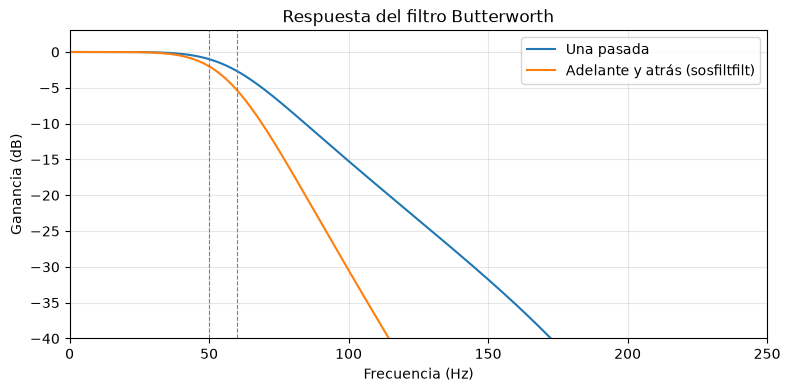

Atenuación total en 50 Hz: -2.0 dB
Atenuación total en 60 Hz: -5.3 dB
Atenuación total en 100 Hz: -30.5 dB


In [28]:
orden, f_corte = signal.buttord(wp=50, ws=60, gpass=1.0, gstop=2.5, fs=FS)
SOS_BUTTER = signal.butter(orden, f_corte, btype="low", fs=FS, output="sos")
print(f"Orden del filtro: {orden}   Frecuencia de corte (-3 dB): {f_corte:.1f} Hz")


def filtro_butterworth(x):
    """Paso 1: Butterworth pasa-bajas aplicado hacia adelante y hacia atrás."""
    return signal.sosfiltfilt(SOS_BUTTER, x)


# Respuesta en frecuencia: una pasada y las dos pasadas de sosfiltfilt
f, h = signal.sosfreqz(SOS_BUTTER, worN=4096, fs=FS)
plt.figure(figsize=(9, 4))
plt.plot(f, 20 * np.log10(np.abs(h) + 1e-12), label="Una pasada")
plt.plot(f, 40 * np.log10(np.abs(h) + 1e-12), label="Adelante y atrás (sosfiltfilt)")
for fr, txt in [(50, "50 Hz"), (60, "60 Hz")]:
    plt.axvline(fr, color="gray", linestyle="--", linewidth=0.8)
plt.ylim(-40, 3); plt.xlim(0, 250)
plt.xlabel("Frecuencia (Hz)"); plt.ylabel("Ganancia (dB)")
plt.title("Respuesta del filtro Butterworth"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

for fr in [50, 60, 100]:
    g = 40 * np.log10(np.abs(signal.sosfreqz(SOS_BUTTER, worN=[fr], fs=FS)[1][0]))
    print(f"Atenuación total en {fr} Hz: {g:.1f} dB")

# LOEES (DERIVA DE LA LINEA BASE)

In [29]:
def loess_robusto(x, span_s, iteraciones=3):
    """LOESS de grado 1 con pesos tricúbicos y robusto (peso 0 fuera de 6 MAD). Devuelve la línea base."""
    n = len(x)
    h = max(int(round(span_s * FS / 2)), 2)               # mitad de la ventana, en muestras
    d = np.arange(-h, h + 1)                               # distancia al punto central
    k = (1 - np.abs(d / (h + 1)) ** 3) ** 3                # pesos tricúbicos

    def suma_ventana(a, nucleo):                           # suma ponderada de 'a' en la ventana de cada punto
        return signal.fftconvolve(a, nucleo[::-1], mode="same")

    r = np.ones(n)                                         # pesos de robustez (al inicio todos valen 1)
    for it in range(iteraciones + 1):
        S0, S1, S2 = suma_ventana(r, k), suma_ventana(r, d * k), suma_ventana(r, d**2 * k)
        T0, T1 = suma_ventana(r * x, k), suma_ventana(r * x, d * k)
        det = S0 * S2 - S1**2
        con_recta = np.abs(det) > 1e-9 * np.maximum(S0 * S2, 1e-12)
        base = np.where(con_recta, (S2 * T0 - S1 * T1) / np.where(con_recta, det, 1), T0 / S0)
        if it == iteraciones:
            return base
        residuo = x - base
        mad = np.median(np.abs(residuo))
        u = residuo / (6 * mad) if mad > 0 else np.zeros(n)
        r = np.where(np.abs(u) < 1, (1 - u**2) ** 2, 0.0)  # bicuadrado: peso 0 si el residuo supera 6 MAD

# NON LOCAL MEANS (NLM)

In [30]:
def sigma_ruido(x):
    """Desviación del ruido, estimada con la MAD de la primera diferencia (robusta a los QRS)."""
    dif = np.diff(x)
    return np.median(np.abs(dif - np.median(dif))) / 0.6745 / np.sqrt(2)


def nlm(x, lam, P=10, M=250):
    """Non-Local Means 1-D con núcleo gaussiano."""
    n = len(x)
    L = 2 * P + 1
    caja = np.ones(L)
    xp = np.pad(x, M, mode="reflect")
    num, den = np.zeros(n), np.zeros(n)
    for m in range(-M, M + 1):                                  # cada desplazamiento de búsqueda
        vecino = xp[M + m: M + m + n]
        distancia = np.convolve((x - vecino) ** 2, caja, mode="same")   # diferencia entre fragmentos
        w = np.exp(-distancia / (2 * L * lam**2))
        num += w * vecino
        den += w
    return num / den

# FLUJO COMPLETO

In [31]:
SPAN_S = 1.0          # ancho de la ventana LOESS (s); se ajusta en la validación
FACTOR_LAMBDA = 1.0   # λ del NLM como múltiplo de la desviación del ruido; se ajusta en la validación


def filtrar_ecg(x, span_s=None, factor_lambda=None, etapas=False):
    span_s = SPAN_S if span_s is None else span_s
    factor_lambda = FACTOR_LAMBDA if factor_lambda is None else factor_lambda
    paso1 = filtro_butterworth(x)
    paso2 = paso1 - loess_robusto(paso1, span_s)
    paso3 = nlm(paso2, factor_lambda * sigma_ruido(paso2))
    if etapas:
        return {"Sin filtrar": x, "Butterworth": paso1, "+ LOESS": paso2, "+ NLM": paso3}
    return paso3

### 3.5 Validación contra `ECGDataDenoised`

In [34]:
def comparar(propia, referencia):
    a, b = propia - np.mean(propia), referencia - np.mean(referencia)
    r = np.corrcoef(a, b)[0, 1]
    nrmse = np.sqrt(np.mean((a - b) ** 2)) / np.std(b)
    return r, nrmse


def referencia_valida(nombre):
    """True si la señal de ECGDataDenoised existe, tiene 5.000 muestras y no está vacía ni plana."""
    ruta = RUTA_DENOISED / f"{nombre}.csv"
    if not ruta.exists():
        return False
    try:
        x = leer_derivacion_ii(nombre, RUTA_DENOISED)
    except Exception:
        return False
    return len(x) == N_MUESTRAS and np.all(np.isfinite(x)) and np.ptp(x) > 0


# Se revisan 30 candidatos por ritmo (no todos, para que sea rápido) y se toman 5 válidos de cada uno
candidatos = pacientes_p2.groupby("Rhythm").sample(30, random_state=42)
candidatos = candidatos[[referencia_valida(n) for n in candidatos["FileName"]]]
validacion = candidatos.groupby("Rhythm").head(5).reset_index(drop=True)

crudas = {n: leer_derivacion_ii(n, RUTA_ECGDATA) for n in validacion["FileName"]}
referencias = {n: leer_derivacion_ii(n, RUTA_DENOISED) for n in validacion["FileName"]}
print("Pacientes de validación:", len(validacion))
print(validacion["Rhythm"].value_counts().reindex(RITMOS))

Pacientes de validación: 25
Rhythm
SB      5
SR      5
AFIB    5
ST      5
SVT     5
Name: count, dtype: int64


In [35]:
filas = []
for span in [0.3, 0.5, 1.0, 2.0]:
    for factor in [0.5, 1.0, 2.0]:
        medidas = [comparar(filtrar_ecg(crudas[n], span, factor), referencias[n]) for n in validacion["FileName"]]
        filas.append([span, factor, np.mean([m[0] for m in medidas]), np.mean([m[1] for m in medidas])])

busqueda = pd.DataFrame(filas, columns=["span (s)", "factor λ", "r promedio", "NRMSE promedio"])
mejor = busqueda.loc[busqueda["r promedio"].idxmax()]
SPAN_S, FACTOR_LAMBDA = float(mejor["span (s)"]), float(mejor["factor λ"])
print(f"Parámetros escogidos: span = {SPAN_S} s, λ = {FACTOR_LAMBDA} × desviación del ruido")
busqueda.round(4)

Parámetros escogidos: span = 0.5 s, λ = 2.0 × desviación del ruido


,span (s),factor λ,r promedio,NRMSE promedio
0,0.3,0.5,0.9698,0.2290
1,0.3,1.0,0.9707,0.2253
2,0.3,2.0,0.9726,0.2164
3,0.5,0.5,0.9897,0.1394
4,0.5,1.0,0.9904,0.1342
5,0.5,2.0,0.9925,0.1173
6,1.0,0.5,0.9852,0.1838
7,1.0,1.0,0.9858,0.1797
8,1.0,2.0,0.9875,0.1662
9,2.0,0.5,0.9724,0.2426


# Aporte de cada etapa

In [36]:
filas = []
for fila in validacion.itertuples():
    for etapa, senal in filtrar_ecg(crudas[fila.FileName], etapas=True).items():
        r, nrmse = comparar(senal, referencias[fila.FileName])
        filas.append([fila.FileName, fila.Rhythm, etapa, r, nrmse])
por_etapa = pd.DataFrame(filas, columns=["Registro", "Ritmo", "Etapa", "r", "NRMSE"])

orden_etapas = ["Sin filtrar", "Butterworth", "+ LOESS", "+ NLM"]
print("Promedio de los 25 pacientes por etapa:")
display(por_etapa.groupby("Etapa")[["r", "NRMSE"]].agg(["mean", "std"]).reindex(orden_etapas).round(4))

print("\nResultado final (+ NLM) por ritmo:")
display(por_etapa[por_etapa["Etapa"] == "+ NLM"].groupby("Ritmo")[["r", "NRMSE"]].mean().reindex(RITMOS).round(4))

Promedio de los 25 pacientes por etapa:


r           NRMSE        
               mean     std    mean     std
Etapa                                      
Sin filtrar  0.9250  0.0986  0.4106  0.3657
Butterworth  0.9426  0.0820  0.3477  0.3223
+ LOESS      0.9896  0.0127  0.1400  0.0717
+ NLM        0.9925  0.0093  0.1173  0.0589


Resultado final (+ NLM) por ritmo:


,r,NRMSE
Ritmo,,
SB,0.9936,0.1067
SR,0.9953,0.0978
AFIB,0.9941,0.1101
ST,0.9839,0.1813
SVT,0.9959,0.0907


# comparacion visual

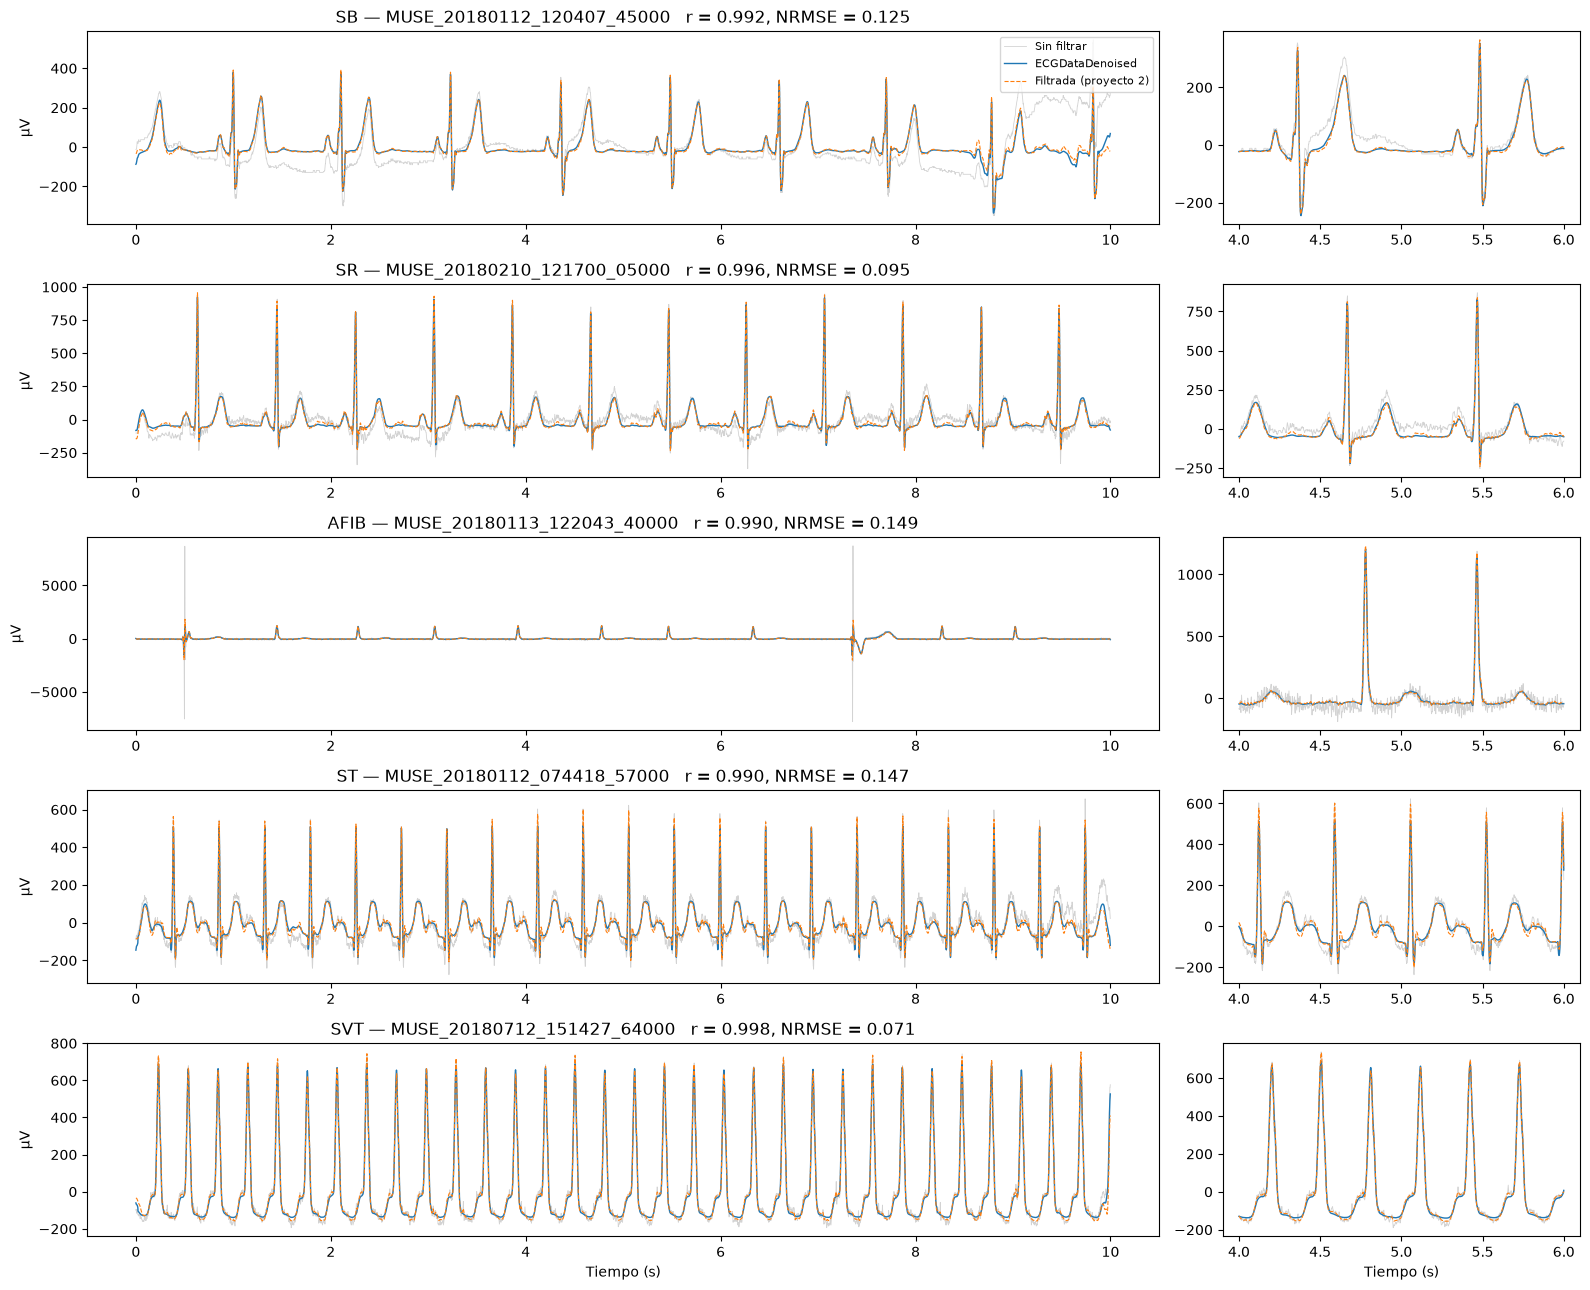

In [37]:
t = np.arange(N_MUESTRAS) / FS
un_paciente = validacion.groupby("Rhythm").head(1).set_index("Rhythm").loc[RITMOS]

fig, ejes = plt.subplots(len(RITMOS), 2, figsize=(16, 2.6 * len(RITMOS)), gridspec_kw={"width_ratios": [3, 1]})
for i, (ritmo, fila) in enumerate(un_paciente.iterrows()):
    cruda, ref = crudas[fila["FileName"]], referencias[fila["FileName"]]
    propia = filtrar_ecg(cruda)
    r, nrmse = comparar(propia, ref)
    for j, (inicio, fin) in enumerate([(0, 10), (4, 6)]):
        eje = ejes[i, j]
        tramo = (t >= inicio) & (t <= fin)
        eje.plot(t[tramo], cruda[tramo] - np.mean(cruda), lw=0.6, color="lightgray", label="Sin filtrar")
        eje.plot(t[tramo], ref[tramo] - np.mean(ref), lw=1.0, label="ECGDataDenoised")
        eje.plot(t[tramo], propia[tramo] - np.mean(propia), lw=0.8, linestyle="--", label="Filtrada (proyecto 2)")
        if j == 0:
            eje.set_title(f"{ritmo} — {fila['FileName']}   r = {r:.3f}, NRMSE = {nrmse:.3f}")
            eje.set_ylabel("µV")
ejes[0, 0].legend(loc="upper right", fontsize=8)
ejes[-1, 0].set_xlabel("Tiempo (s)"); ejes[-1, 1].set_xlabel("Tiempo (s)")
plt.tight_layout()
plt.show()

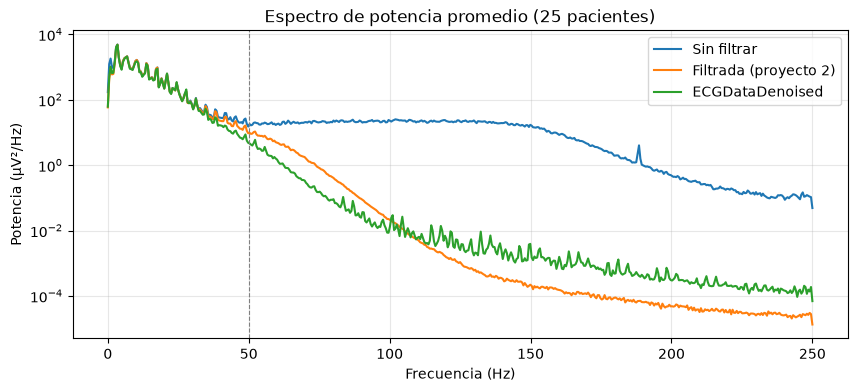

In [38]:
# Espectro de potencia promedio de los 25 pacientes: sin filtrar, filtrada y referencia
espectros = {"Sin filtrar": [], "Filtrada (proyecto 2)": [], "ECGDataDenoised": []}
for n in validacion["FileName"]:
    for nombre, senal in [("Sin filtrar", crudas[n]), ("Filtrada (proyecto 2)", filtrar_ecg(crudas[n])),
                          ("ECGDataDenoised", referencias[n])]:
        f, P = signal.welch(senal - np.mean(senal), fs=FS, nperseg=1024)
        espectros[nombre].append(P)

plt.figure(figsize=(10, 4))
for nombre, lista in espectros.items():
    plt.semilogy(f, np.mean(lista, axis=0), label=nombre)
plt.axvline(50, color="gray", linestyle="--", linewidth=0.8)
plt.xlabel("Frecuencia (Hz)"); plt.ylabel("Potencia (µV²/Hz)")
plt.title("Espectro de potencia promedio (25 pacientes)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

# APLICACION DE FILTRADO DE TODAS LAS SEÑALES

In [40]:
RUTA_FILTRADAS = Path("senales_filtradas_II.npy")

if RUTA_FILTRADAS.exists():
    senales_filtradas = np.load(RUTA_FILTRADAS)
    print("Señales cargadas desde", RUTA_FILTRADAS, "->", senales_filtradas.shape)
else:
    senales_filtradas = np.zeros((len(pacientes_p2), N_MUESTRAS), dtype=np.float32)
    inicio = time.time()
    for i, nombre in enumerate(pacientes_p2["FileName"]):
        senales_filtradas[i] = filtrar_ecg(leer_derivacion_ii(nombre, RUTA_ECGDATA))
        if (i + 1) % 500 == 0:
            print(f"{i + 1} de {len(pacientes_p2)} filtradas ({time.time() - inicio:.0f} s)")
    np.save(RUTA_FILTRADAS, senales_filtradas)
    print("Señales guardadas en", RUTA_FILTRADAS, "->", senales_filtradas.shape)

500 de 8288 filtradas (66 s)
1000 de 8288 filtradas (132 s)
1500 de 8288 filtradas (192 s)
2000 de 8288 filtradas (254 s)
2500 de 8288 filtradas (317 s)
3000 de 8288 filtradas (871 s)
3500 de 8288 filtradas (935 s)
4000 de 8288 filtradas (998 s)
4500 de 8288 filtradas (1059 s)
5000 de 8288 filtradas (1121 s)
5500 de 8288 filtradas (1184 s)
6000 de 8288 filtradas (1266 s)
6500 de 8288 filtradas (1347 s)
7000 de 8288 filtradas (1425 s)
7500 de 8288 filtradas (1506 s)
8000 de 8288 filtradas (1583 s)
Señales guardadas en senales_filtradas_II.npy -> (8288, 5000)
